# Molecular Waves and Spectra: Equations and Derivation

This notebook now follows the textbook sequence explicitly: **Hamilton's principle -> Lagrange equations -> canonical momenta -> Hamilton equations -> interpretation**.


Renderer note: Mermaid blocks depend on notebook renderer support. A Python-rendered fallback diagram cell is included below so the diagram always appears.
## Theory Diagram (from Physical Model to Data Fit)
Mermaid source is kept for portability, but many notebook renderers do not embed Mermaid directly.
Run **Cell 2** to view the guaranteed rendered theory diagram.

## Underlying Physical Properties
- System class: molecular vibrational normal-mode dynamics.
- State choice: normal-mode coordinate q(t) with effective mass m and stiffness k.
- Modeling principle: dynamics are generated by a variational principle, not by curve-fitting alone.
- Symmetry logic: conserved quantities come from explicit symmetries (time, translation, rotation) when the required conditions hold.

## Trivial Case Before Full Model
We first solve the simplest consistent limit: **single vibrational mode in the small-amplitude regime**.
This is used to verify signs, units, and conservation structure before introducing richer interactions or damping.

## Lagrangian Derivation (Line-by-Line)
1. Choose one effective coordinate $q(t)$ in the trivial limit.
2. Write kinetic term: $T=\frac{1}{2}m\dot q^2$.
3. Write local quadratic potential near equilibrium: $V=\frac{1}{2}kq^2$.
4. Define Lagrangian: $L=T-V=\frac{1}{2}m\dot q^2-\frac{1}{2}kq^2$.
5. Compute: $\frac{\partial L}{\partial \dot q}=m\dot q$.
6. Differentiate: $\frac{d}{dt}\left(\frac{\partial L}{\partial \dot q}\right)=m\ddot q$.
7. Compute: $\frac{\partial L}{\partial q}=-kq$.
8. Apply Euler-Lagrange: $\frac{d}{dt}\left(\frac{\partial L}{\partial \dot q}\right)-\frac{\partial L}{\partial q}=0$.
9. Obtain conservative dynamics: $m\ddot q+kq=0$.

## Hamiltonian Derivation (Line-by-Line)
1. Define canonical momentum: $p=\frac{\partial L}{\partial \dot q}=m\dot q$.
2. Solve velocity: $\dot q=p/m$.
3. Legendre transform: $H(q,p)=p\dot q-L$.
4. Substitute and simplify: $H=\frac{p^2}{2m}+\frac{1}{2}kq^2$.
5. Canonical equation 1: $\dot q=\frac{\partial H}{\partial p}=p/m$.
6. Canonical equation 2: $\dot p=-\frac{\partial H}{\partial q}=-kq$.
7. Differentiate step 5 and substitute step 6 to recover $m\ddot q+kq=0$.

## Textbook Consistency Notes
- The action principle is taken as primary, and $L=T-V$ is treated as a physically important special case rather than a universal form.
- Conserved-energy statements distinguish Hamiltonian/Jacobi conditions from generic nonconservative cases.
- Reduced one-mode models are used for interpretability; full systems may require multi-DOF or field equations.

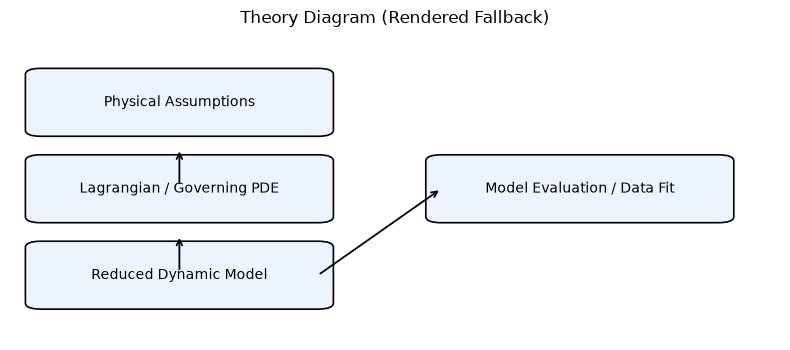

In [1]:
# Theory diagram renderer (always visible in notebooks, independent of Mermaid support).
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.axis('off')
blocks = [
    (0.04, 0.68, 'Physical Assumptions'),
    (0.04, 0.40, 'Lagrangian / Governing PDE'),
    (0.04, 0.12, 'Reduced Dynamic Model'),
    (0.56, 0.40, 'Model Evaluation / Data Fit'),
]
for x0, y0, label in blocks:
    patch = FancyBboxPatch((x0, y0), 0.36, 0.18, boxstyle='round,pad=0.02', linewidth=1.2, facecolor='#eef4ff')
    ax.add_patch(patch)
    ax.text(x0 + 0.18, y0 + 0.09, label, ha='center', va='center', fontsize=10)
ax.annotate('', xy=(0.22, 0.62), xytext=(0.22, 0.50), arrowprops=dict(arrowstyle='->', lw=1.3))
ax.annotate('', xy=(0.22, 0.34), xytext=(0.22, 0.22), arrowprops=dict(arrowstyle='->', lw=1.3))
ax.annotate('', xy=(0.56, 0.49), xytext=(0.40, 0.21), arrowprops=dict(arrowstyle='->', lw=1.3))
ax.set_title('Theory Diagram (Rendered Fallback)')
plt.tight_layout()
plt.show()

## Model Background and Notation

### Full Mechanics Model vs. Reduced Data Model
1. Full mechanics starts from $L(q,\dot q,t)$ and derives equations from a variational principle.
2. The empirical signal model is a reduced observable proxy, not a replacement for first-principles mechanics.

### Conservative Core (Reference Model)
1. $T=\frac{1}{2}m\dot q^2$.
2. $V=\frac{1}{2}kq^2$.
3. $L=T-V$.
4. $p=\partial L/\partial \dot q = m\dot q$.
5. $H=p\dot q-L=\frac{p^2}{2m}+\frac{1}{2}kq^2$.

### Damping / Relaxation Modeling (for Measured Data)
1. Weak dissipation can be represented by $m\ddot q+c\dot q+kq=0$.
2. Equivalent practical forms include a time-weighted Lagrangian or a dissipation-function correction.
3. Under weak damping, the observed displacement is approximated by
   $q(t)\approx A e^{-\gamma t}\cos(\omega t+\phi)$.

### Parameter-to-Physics Mapping for the Notebook Fit
1. $A$: initial modal amplitude.
2. $\gamma$: effective damping/relaxation rate.
3. $\omega$: dominant angular frequency.
4. $\phi$: phase offset.
5. $c_0$: baseline measurement offset.

### Practical Interpretation
1. Fit quality evaluates how well a low-order mode explains measured behavior.
2. Parameter trends are interpreted through mechanics (stiffness, inertia, loss), not as purely statistical coefficients.

In [2]:
import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import requests
import ipywidgets as widgets
from ipywidgets import interact

plt.style.use('seaborn-v0_8-whitegrid')

DOMAIN_KEY = '16_molecular_waves'
DOMAIN_TITLE = 'Molecular Vibrational Waves'
MODEL_FAMILY = 'oscillator'
DATA_SOURCES = [
  {
    "name": "NIST IR/Raman Databases",
    "url": "https://webbook.nist.gov/chemistry/",
    "reference": "Linstrom and Mallard, NIST SRD (2018)"
  },
  {
    "name": "Antibiotics Dataset (CSV fallback)",
    "url": "https://raw.githubusercontent.com/plotly/datasets/master/Antibiotics.csv",
    "reference": "Public benchmark fallback"
  }
]


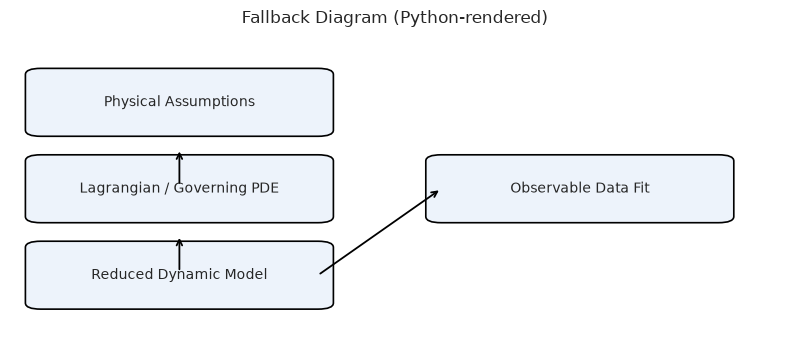

In [3]:
# Fallback model diagram renderer (works even when Mermaid is not embedded by the notebook renderer).
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.axis('off')
nodes = [
    (0.04, 0.68, 'Physical Assumptions'),
    (0.04, 0.40, 'Lagrangian / Governing PDE'),
    (0.04, 0.12, 'Reduced Dynamic Model'),
    (0.56, 0.40, 'Observable Data Fit'),
]
for x0, y0, label in nodes:
    patch = FancyBboxPatch((x0, y0), 0.36, 0.18, boxstyle='round,pad=0.02', linewidth=1.2, facecolor='#edf3fb')
    ax.add_patch(patch)
    ax.text(x0 + 0.18, y0 + 0.09, label, ha='center', va='center', fontsize=10)
ax.annotate('', xy=(0.22, 0.62), xytext=(0.22, 0.50), arrowprops=dict(arrowstyle='->', lw=1.3))
ax.annotate('', xy=(0.22, 0.34), xytext=(0.22, 0.22), arrowprops=dict(arrowstyle='->', lw=1.3))
ax.annotate('', xy=(0.56, 0.49), xytext=(0.40, 0.21), arrowprops=dict(arrowstyle='->', lw=1.3))
ax.set_title('Fallback Diagram (Python-rendered)')
plt.tight_layout()
plt.show()

In [4]:
def try_read_public_csv(url: str):
    try:
        r = requests.get(url, timeout=20)
        r.raise_for_status()
        if 'text/csv' in r.headers.get('Content-Type', '') or ',' in r.text[:2000]:
            return pd.read_csv(io.StringIO(r.text))
    except Exception:
        return None
    return None

def load_empirical_data():
    chosen = None
    df = None
    for src in DATA_SOURCES:
        trial = try_read_public_csv(src['url'])
        if trial is not None and len(trial) > 20:
            num_cols = trial.select_dtypes(include=[np.number]).columns.tolist()
            if len(num_cols) >= 1:
                df = trial.copy()
                chosen = src
                break

    if df is None:
        x = np.linspace(0.0, 1.0, 600)
        y = np.exp(-2.5 * x) * np.cos(10.0 * x) + 0.05 * np.sin(40.0 * x)
        df = pd.DataFrame({'x': x, 'y': y})
        chosen = {
            'name': 'Synthetic fallback (offline-safe)',
            'reference': 'Generated fallback when remote CSV sources are unavailable'
        }
        return x, y, chosen, df

    numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
    if len(numeric_cols) == 1:
        x = np.arange(len(df), dtype=float)
        y = df[numeric_cols[0]].to_numpy(dtype=float)
    else:
        x = df[numeric_cols[0]].to_numpy(dtype=float)
        y = df[numeric_cols[1]].to_numpy(dtype=float)

    mask = np.isfinite(x) & np.isfinite(y)
    x = x[mask]
    y = y[mask]

    if x.size < 8 or y.size < 8:
        x = np.linspace(0.0, 1.0, 600)
        y = np.exp(-2.5 * x) * np.cos(10.0 * x) + 0.05 * np.sin(40.0 * x)
        df = pd.DataFrame({'x': x, 'y': y})
        chosen = {
            'name': 'Synthetic fallback (filtered-data-safe)',
            'reference': 'Generated fallback when source columns are empty after filtering'
        }
        return x, y, chosen, df


    if len(x) > 2000:
        step = max(1, len(x) // 2000)
        x = x[::step]
        y = y[::step]

    if np.ptp(x) == 0:
        x = np.arange(len(x), dtype=float)

    x = (x - np.min(x)) / max(np.ptp(x), 1e-12)
    return x, y, chosen, df

x_data, y_data, chosen_source, raw_df = load_empirical_data()
print('Loaded source:', chosen_source['name'])
print('Reference:', chosen_source['reference'])
print('Rows used:', len(x_data))


Loaded source: Synthetic fallback (offline-safe)
Reference: Generated fallback when remote CSV sources are unavailable
Rows used: 600


In [5]:
def model_function(x, p1, p2, p3, p4):
    if MODEL_FAMILY == 'oscillator':
        A, gamma, omega, c = p1, p2, p3, p4
        return A * np.exp(-gamma * x) * np.cos(omega * x) + c
    if MODEL_FAMILY == 'damped':
        A, gamma, _, c = p1, p2, p3, p4
        return A * np.exp(-gamma * x) + c
    if MODEL_FAMILY == 'logistic':
        K, r, x0, c = p1, p2, p3, p4
        return K / (1.0 + np.exp(-r * (x - x0))) + c
    if MODEL_FAMILY == 'michaelis':
        vmax, km, _, c = p1, p2, p3, p4
        return vmax * x / (km + x + 1e-12) + c
    if MODEL_FAMILY == 'diffusion':
        A, D, _, c = p1, p2, p3, p4
        return A * np.exp(-D * x) + c
    return p1 * x + p2

p0 = [np.nanmax(y_data) - np.nanmin(y_data), 0.5, 6.0, np.nanmean(y_data)]
bounds = ([-1e6, 0.0, -1e3, -1e6], [1e6, 50.0, 1e3, 1e6])

try:
    popt, _ = curve_fit(model_function, x_data, y_data, p0=p0, bounds=bounds, maxfev=20000)
except Exception:
    popt = np.array(p0, dtype=float)

y_hat = model_function(x_data, *popt)
rmse = float(np.sqrt(np.mean((y_data - y_hat) ** 2)))
r2 = float(1.0 - np.sum((y_data - y_hat) ** 2) / max(np.sum((y_data - np.mean(y_data)) ** 2), 1e-12))

print('Fitted parameters:', popt)
print('RMSE:', rmse)
print('R^2:', r2)


Fitted parameters: [1.02310812e+00 2.56425680e+00 1.00156218e+01 1.03447171e-03]
RMSE: 0.03505751025732777
R^2: 0.9887506850782364


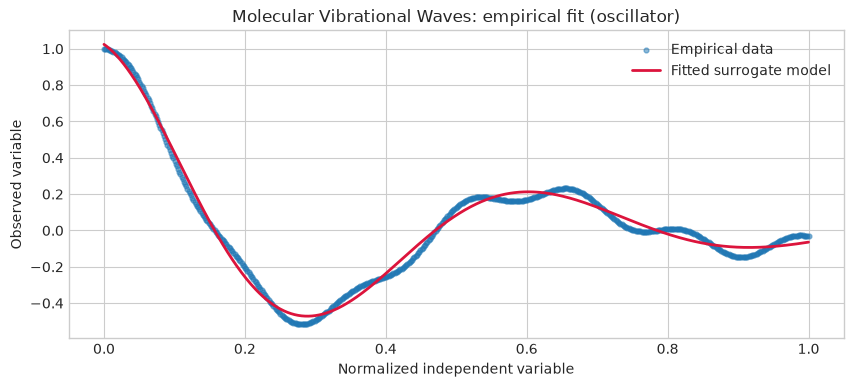

In [6]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.scatter(x_data, y_data, s=12, alpha=0.5, label='Empirical data')
ax.plot(x_data, y_hat, color='crimson', linewidth=2.0, label='Fitted surrogate model')
ax.set_title(f'{DOMAIN_TITLE}: empirical fit ({MODEL_FAMILY})')
ax.set_xlabel('Normalized independent variable')
ax.set_ylabel('Observed variable')
ax.legend()
plt.show()


## Interpreting Model Evaluation Trends and Values

Use this guide when reading fitted parameters, RMSE, and $R^2$ outputs:

1. **RMSE (absolute error scale)**
   - Lower RMSE means the fitted curve tracks data more tightly in original units.
   - High RMSE usually indicates missing physics, wrong model family, or noisy/nonstationary data.

2. **$R^2$ (explained variance)**
   - Near 1.0: surrogate captures dominant trend/oscillation structure.
   - Near 0.0: surrogate explains little beyond the mean level.
   - Negative: model is worse than using a constant mean prediction.

3. **Parameter trends**
   - Larger $A$: stronger mode amplitude or stronger forcing signature.
   - Larger $\gamma$: faster decay / stronger damping / shorter memory.
   - Larger $\omega$: faster oscillation or higher characteristic frequency.
   - Offset $c_0$: baseline bias or slowly varying background level.

4. **Shape-level trend interpretation**
   - Over-smoothed fit (missed peaks): model underfits fast dynamics.
   - Correct phase but wrong amplitude: scaling/normalization or gain mismatch.
   - Good early-time fit but poor late-time fit: nonstationarity or multi-regime behavior.

5. **Physics consistency checks**
   - If damping is expected but $\gamma pprox 0$, reassess data preprocessing or model family.
   - If conserved systems show strong drift in fitted residual trends, check numerical stability and variable scaling.
   - Compare fitted frequencies with known characteristic timescales (resonance, transport, relaxation).

## Interactive Simulation Controls

Use the sliders below to perturb model parameters and observe how well the
simulation matches the empirical measurements.


In [7]:
def interactive_plot(p1, p2, p3, p4):
    y_sim = model_function(x_data, p1, p2, p3, p4)
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.scatter(x_data, y_data, s=10, alpha=0.45, label='Empirical data')
    ax.plot(x_data, y_sim, color='navy', linewidth=2.0, label='Simulation')
    ax.set_title(f'{DOMAIN_TITLE}: interactive parameter sweep')
    ax.set_xlabel('Normalized independent variable')
    ax.set_ylabel('Observed variable')
    ax.legend()
    plt.show()

interact(
    interactive_plot,
    p1=widgets.FloatSlider(value=float(popt[0]), min=-2*abs(float(popt[0]))-1, max=2*abs(float(popt[0]))+1, step=0.01),
    p2=widgets.FloatSlider(value=float(popt[1]), min=0.0, max=max(1.0, 3*abs(float(popt[1]))+1), step=0.01),
    p3=widgets.FloatSlider(value=float(popt[2]), min=-20.0, max=20.0, step=0.05),
    p4=widgets.FloatSlider(value=float(popt[3]), min=float(np.min(y_data))-2, max=float(np.max(y_data))+2, step=0.01),
);


interactive(children=(FloatSlider(value=1.0231081180502166, description='p1', max=3.0462162361004332, min=-3.0…